# YOLO on video: cars on a highway

### Key words

| Word | Meaning | Example |
|---|---|---|
| Frame | One image of the video | Frame 0, frame 1, ... |
| FPS | Frames per second | 30 FPS = 30 images per second |
| Detection | A box, a name and a confidence for each object | `car 0.85` |
| Segmentation | The exact shape of each object | The car's outline, coloured |
| Tracking | The same ID for the same object in every frame | `id:7` stays on one car |
| OpenCV (`cv2`) | A library that reads and writes images and videos | `cv2.VideoCapture(VIDEO)` |
| `mp4v` | The video format used for the saved videos | `outputs/1_detection.mp4` |
| Solutions | Ready-made Ultralytics tools built on tracking | `solutions.ObjectCounter` |
| shapely | A geometry library used by the Solutions, e.g. to check if a car crosses a line | Line from (0, 450) to (1280, 450) |
| lap | A library that matches boxes between frames, used by tracking | Box 3 in frame 1 = `id:7` |
| Metres per pixel | How many metres one pixel covers on the road, used for speed | `0.05` = 5 cm |
| Visual prompt | An example box instead of words | A box around one white car |
| Prompt-free | A model that names objects without any prompt | `yoloe-26n-seg-pf.pt` |

### Which model does what

| Model | Boxes | Shapes | Tracking | Looks for |
|---|---|---|---|---|
| `yolo26n.pt` | Yes | No | Yes | Fixed list of 80 |
| `yolo26n-seg.pt` | Yes | Yes | Yes | Fixed list of 80 |
| `yoloe-26n-seg.pt` | Yes | Yes | Yes | **Words** or a **picture example** |
| `yoloe-26n-seg-pf.pt` | Yes | Yes | Yes | Built-in list of thousands (no prompt) |

Counting and speed are built on tracking.

## 0. Setup
Run this cell once. Expected output: `True`.

`run_video(step, name)` gives each frame to `step`, saves the video and shows the last frame. Each section defines only its own `step`.

**Real time:** each step prints its speed. It is real time when it processes at least as many frames per second as the video has (30).

**Live view:** with `LIVE = True`, a window shows each frame while it is processed, as with a real camera. Press `q` in the window to stop early. Set `LIVE = False` to switch it off.

In [24]:
import sys
print("Using this folder's uv environment:", ".venv" in sys.executable)

import os, time
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import YOLO, YOLOE, solutions

VIDEO = "video_example_1.mp4"  # or "video_example_2.mp4"
SECONDS = 4  # use only the first seconds
VEHICLES = [2, 3, 5, 7]  # car, motorcycle, bus, truck in YOLO's list
LIVE = True  # True = also show each frame in a window while it is processed

cap = cv2.VideoCapture(VIDEO)
FPS = cap.get(cv2.CAP_PROP_FPS)
SIZE = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
ok, FIRST = cap.read()  # the first frame
cap.release()
FRAMES = int(FPS * SECONDS)
os.makedirs("outputs", exist_ok=True)


def show_frame(frame, title):
    plt.figure(figsize=(10, 6))
    plt.imshow(frame[:, :, ::-1])  # [:, :, ::-1] fixes the colours
    plt.title(title)
    plt.axis("off")
    plt.show()


def run_video(step, name):
    cap = cv2.VideoCapture(VIDEO)
    out = cv2.VideoWriter(f"outputs/{name}.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, SIZE)
    start = time.time()
    for _ in range(FRAMES):
        ok, frame = cap.read()
        if not ok:
            break

        ############
        # Here we add the model output processing
        drawn = step(frame)
        ############

        out.write(drawn)
        if LIVE:  # live view: press q in the window to stop
            cv2.imshow("YOLO live view (press q to stop)", drawn)
            if cv2.waitKey(1) == ord("q"):
                break
    cap.release()
    out.release()
    cv2.destroyAllWindows()
    show_frame(drawn, f"{name} (last frame)")
    print(f"Speed: {FRAMES / (time.time() - start):.0f} frames per second (the video has {FPS:.0f})")

Using this folder's uv environment: True


## 1. Look at the video

video_example_1.mp4 (1280, 720) 30.0 FPS | 120 frames


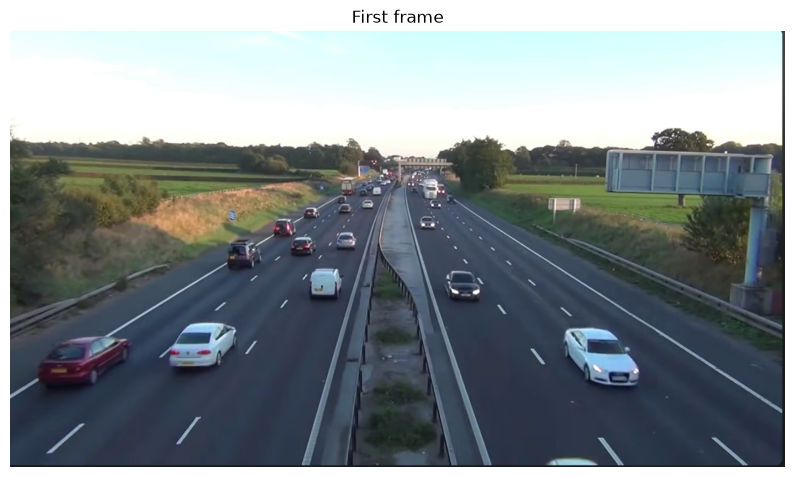

In [25]:
print(VIDEO, SIZE, FPS, "FPS |", FRAMES, "frames")
show_frame(FIRST, "First frame")

---
# Part 1: YOLO

## 2. Detection
A box, a name and a confidence for each vehicle.

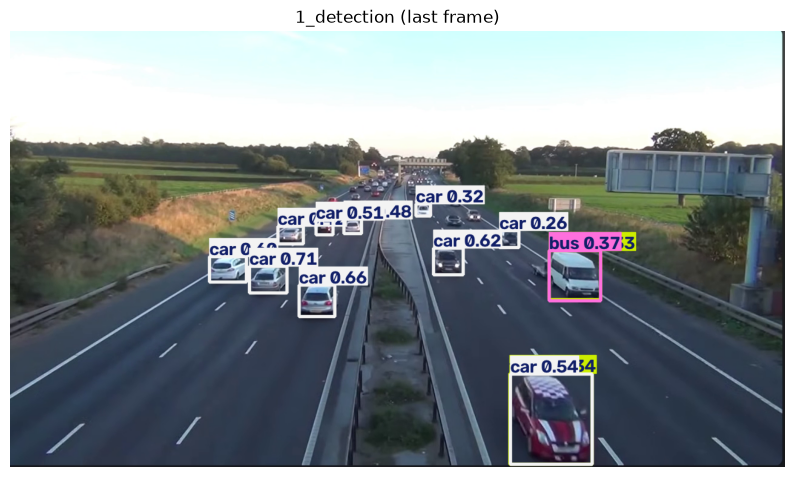

Speed: 30 frames per second (the video has 30)


In [21]:
model = YOLO("yolo26n.pt")

def step(frame):
    return model(frame, classes=VEHICLES, verbose=False)[0].plot()

run_video(step, "1_detection")

## 3. Segmentation
The exact shape of each vehicle. Same code, different model.

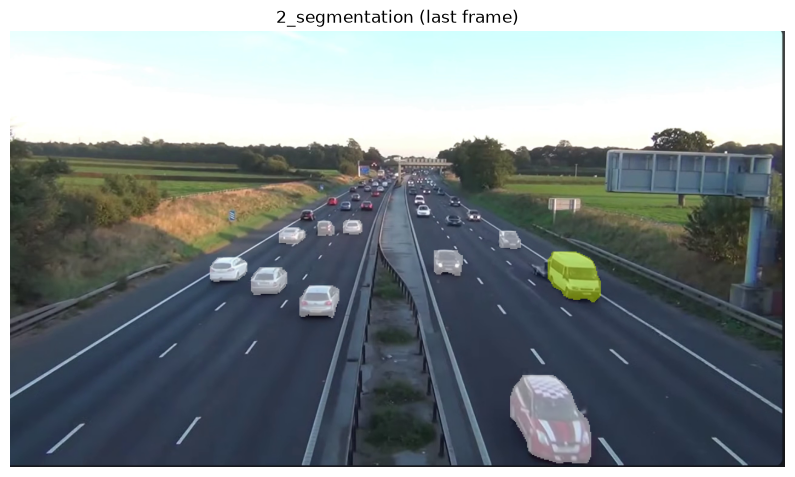

Speed: 11 frames per second (the video has 30)


In [22]:
model = YOLO("yolo26n-seg.pt")


def step(frame):
    return model(frame, classes=VEHICLES, verbose=False)[0].plot(boxes=False)


run_video(step, "2_segmentation")

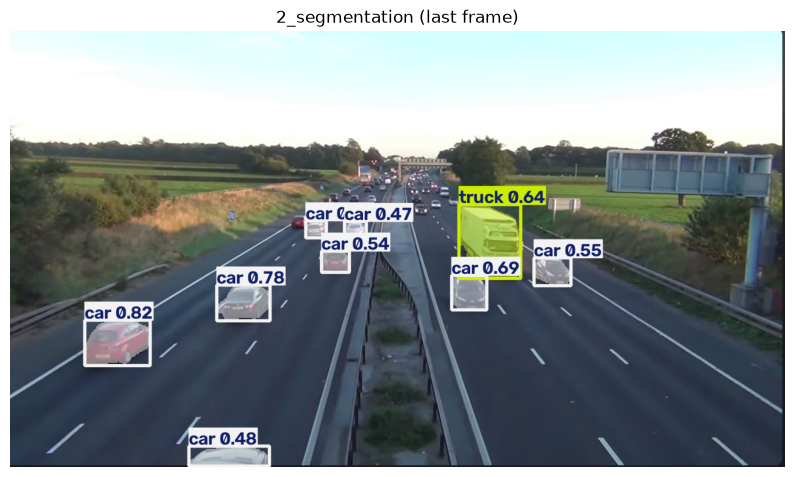

Speed: 14 frames per second (the video has 30)


In [26]:
model = YOLO("yolo26n-seg.pt")


def step(frame):
    return model(frame, classes=VEHICLES, verbose=False)[0].plot(boxes=True)


run_video(step, "2_segmentation")

## 4. Tracking
Each vehicle keeps the same ID in every frame. Example: `id:7` stays on one car.
The only change: `model.track(...)` instead of `model(...)`.

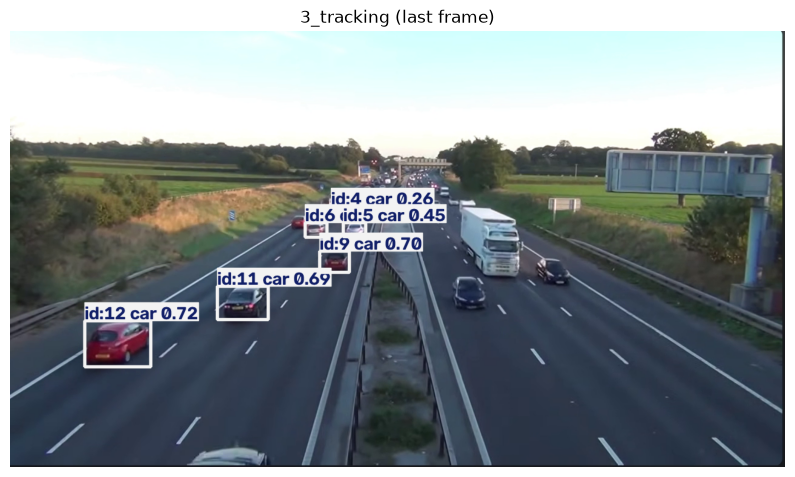

Speed: 24 frames per second (the video has 30)


In [ ]:
model = YOLO("yolo26n.pt")
seen = {}  # ID -> vehicle type
on_screen = []  # vehicles in each frame


def step(frame):
    r = model.track(frame, persist=True, classes=VEHICLES, verbose=False)[0]
    on_screen.append(len(r.boxes))
    if r.boxes.id is not None:
        for i, c in zip(r.boxes.id.int().tolist(), r.boxes.cls.int().tolist()):
            seen[i] = r.names[c]
    return r.plot()


run_video(step, "3_tracking")

## 5. Understanding
This section converts the tracking results into simple facts. A lost vehicle may get a new ID, so totals can be a little high.

Different vehicles in 4 s: 11
car    11
Most at once: 7 at second 3.6


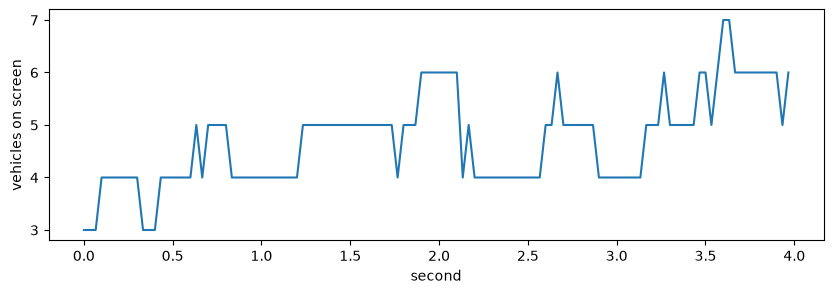

In [32]:
print(f"Different vehicles in {SECONDS} s:", len(seen))
print(pd.Series(seen).value_counts().to_string())
print("Most at once:", max(on_screen), "at second", round(on_screen.index(max(on_screen)) / FPS, 1))

plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(on_screen)) / FPS, on_screen)
plt.xlabel("second")
plt.ylabel("vehicles on screen")
plt.show()

## 6. Counting
Vehicles are counted when they cross a line. **IN** and **OUT** are the two directions (the two sides of the highway).

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': [(0, 400), (1280, 400)], 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


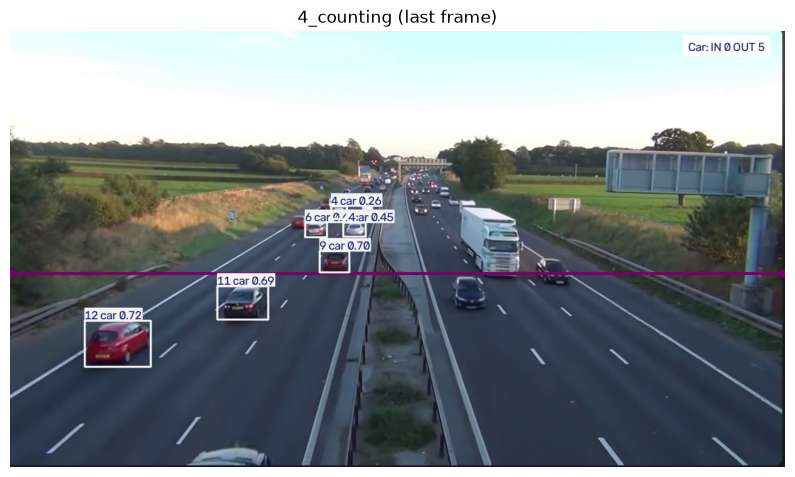

Speed: 24 frames per second (the video has 30)
IN: 0 | OUT: 5


In [34]:
PARAM = 400
LINE = [(0, PARAM), (SIZE[0], PARAM)]  # PARAM pixels from the top
counter = solutions.ObjectCounter(model="yolo26n.pt", region=LINE, classes=VEHICLES, show=False, verbose=False)


def step(frame):
    return counter.process(frame).plot_im


run_video(step, "4_counting")
print("IN:", counter.in_count, "| OUT:", counter.out_count)

## 7. Speed
Speed = distance ÷ time. Distance is in pixels, so an estimated scale, `METERS_PER_PIXEL`, is used (0.05 = 1 pixel ≈ 5 cm).
It is a **rough** estimate: far vehicles look slower.

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 200, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


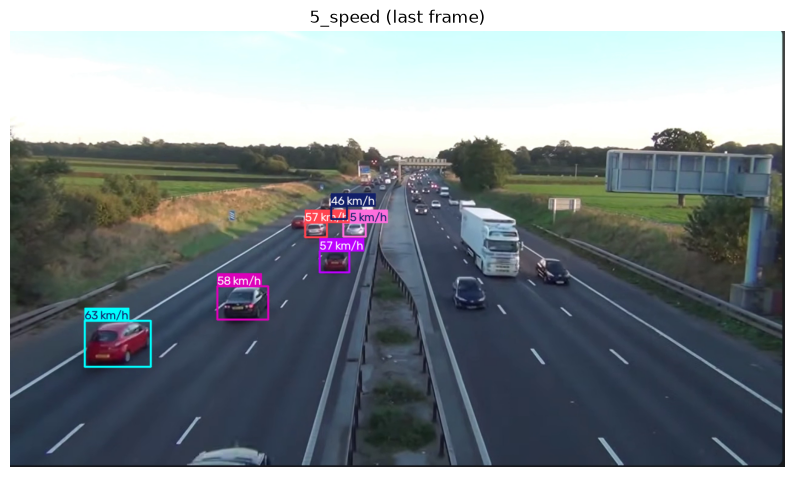

Speed: 23 frames per second (the video has 30)
Vehicles measured: 11 | average: 55 km/h


In [36]:
METERS_PER_PIXEL = 0.05  # this could be a bad estimator, we would need to have a better realistic estimation
speed = solutions.SpeedEstimator(model="yolo26n.pt", classes=VEHICLES, fps=FPS, meter_per_pixel=METERS_PER_PIXEL,max_speed=200, show=False, verbose=False)
speeds = {}  # ID -> km/h


def step(frame):
    r = speed.process(frame)
    speeds.update(r.speed_dict)
    return r.plot_im

run_video(step, "5_speed")
print("Vehicles measured:", len(speeds), "| average:", round(np.mean(list(speeds.values()))), "km/h")

---
# Part 2: YOLOE

## 8. Words
YOLOE searches for the given words. Example: YOLO only knows `car`; YOLOE can look for a `white car`.

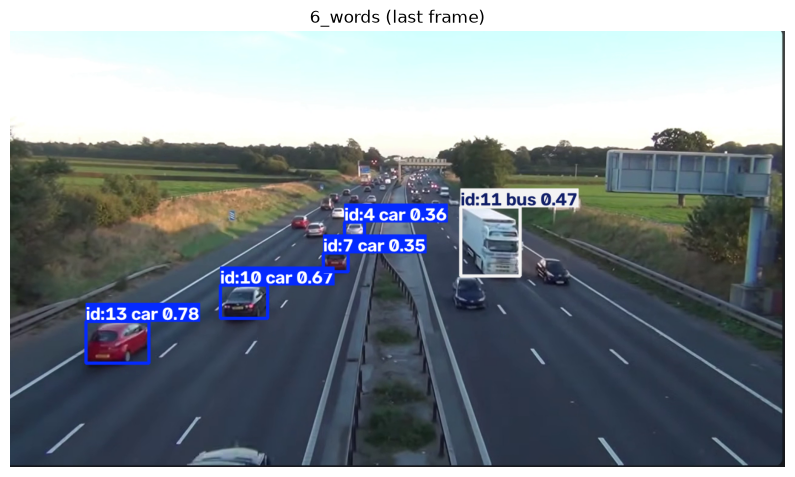

Speed: 21 frames per second (the video has 30)
car    12
bus     1


In [39]:
model = YOLOE("yoloe-26n-seg.pt")
model.set_classes(["car", "truck", "bus"])
seen = {}  # ID -> word


def step(frame):
    r = model.track(frame, persist=True, conf=0.25, verbose=False)[0]
    if r.boxes.id is not None:
        for i, c in zip(r.boxes.id.int().tolist(), r.boxes.cls.int().tolist()):
            seen[i] = r.names[c]
    return r.plot(masks=False)


run_video(step, "6_words")
print(pd.Series(seen).value_counts().to_string())

## 12. Safety, security and compliance

| Word | Meaning | Example |
|---|---|---|
| Safety | Protecting people from accidents | Alert when a worker has no helmet |
| Security | Protecting places and systems | Alert when a vehicle enters a closed area |
| Compliance | Following laws, privacy rules and licences | Blur faces and number plates |

---
# Part 4: More Solutions

**Solutions** are ready-made Ultralytics tools built on YOLO tracking. All of them are used in the same way:
1. Create the tool once. Example: `counter = solutions.ObjectCounter(...)`
2. Give it every frame. Example: `counter.process(frame)`
3. Read the drawn frame from `.plot_im`.

| Solution | What it does | Example use | In this notebook |
|---|---|---|---|
| `ObjectCounter` | Counts objects that cross a line | Vehicles per direction | Section 6 |
| `SpeedEstimator` | Estimates the speed of each object | Traffic speed | Section 7 |
| `Heatmap` | Colours the areas with the most traffic | Busiest lanes | Section 13 |
| `RegionCounter` | Counts the objects inside several areas | Vehicles on each side of the road | Section 14 |
| `QueueManager` | Counts the objects waiting in one area | People in a queue | Same idea as section 14 |
| `TrackZone` | Tracks objects only inside one area | Watch one side of the road | Section 15 |
| `VisionEye` | Draws a line from one point to each object | View from a camera position | Section 16 |
| `Analytics` | Draws a chart of the counts over time | Traffic over time | Section 17 |
| `ObjectBlurrer` | Blurs the objects | Privacy | Section 18 |
| `InstanceSegmentation` | Draws the shape of each object | Same result as section 3 | Section 3 |
| `ObjectCropper` | Saves each object as a small image file | Collecting examples | Not run: creates many files |
| `DistanceCalculation` | Measures the distance between two objects | Space between vehicles | Not run: needs mouse clicks |
| `ParkingManagement` | Shows free and occupied parking spaces | Car parks | Not run: needs a file with the spaces |
| `SecurityAlarm` | Sends an e-mail when objects appear | Night security | Not run: needs an e-mail account |
| `AIGym` | Counts exercise repetitions | Fitness | Not run: needs a video of a person |
| `VisualAISearch`, `Inference` | Image search and a web application | Demos | Not run: need extra libraries |

## 13. Heatmap
Areas where many vehicles pass become warmer (red). Example: the busiest lanes.

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 2, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


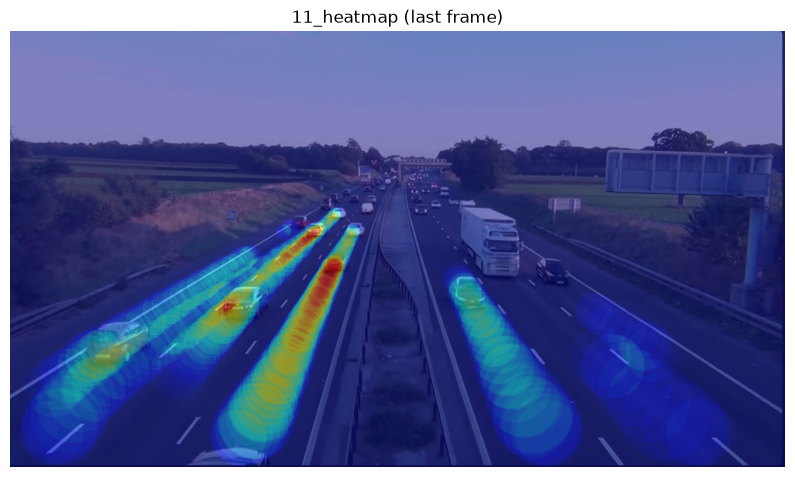

Speed: 21 frames per second (the video has 30)


In [40]:
heatmap = solutions.Heatmap(model="yolo26n.pt", classes=VEHICLES, colormap=cv2.COLORMAP_JET, show=False, verbose=False)


def step(frame):
    return heatmap.process(frame).plot_im


run_video(step, "11_heatmap")

## 14. Region counter
Counts the vehicles inside each area at every moment. Each area is a list of corner points (x, y).

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': {'Left road': [(0, 250), (620, 250), (620, 720), (0, 720)], 'Right road': [(660, 250), (1280, 250), (1280, 720), (660, 720)]}, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


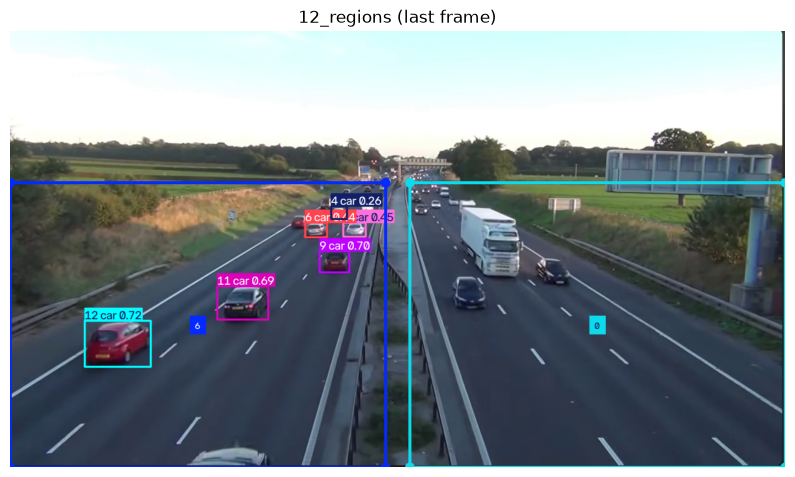

Speed: 23 frames per second (the video has 30)
Vehicles in each area (last frame): {'Left road': 6, 'Right road': 0}


In [42]:
REGIONS = {
    "Left road": [(0, 250), (620, 250), (620, 720), (0, 720)],
    "Right road": [(660, 250), (1280, 250), (1280, 720), (660, 720)],
}
regions = solutions.RegionCounter(model="yolo26n.pt", region=REGIONS, classes=VEHICLES, show=False, verbose=False)


def step(frame):
    return regions.process(frame).plot_im


run_video(step, "12_regions")
print("Vehicles in each area (last frame):", regions.region_counts)

In [51]:
REGIONS = {
    "Left road": [(0, 250), (620, 250), (620, 720), (0, 720)],
    "Right road": [(660, 250), (1280, 250), (1280, 720), (660, 720)],
    "Left small road": [(150, 340), (520, 340), (520, 640), (150, 640)],
}

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': {'Left road': [(0, 250), (620, 250), (620, 720), (0, 720)], 'Right road': [(660, 250), (1280, 250), (1280, 720), (660, 720)], 'Left small road': [(150, 340), (520, 340), (520, 640), (150, 640)]}, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


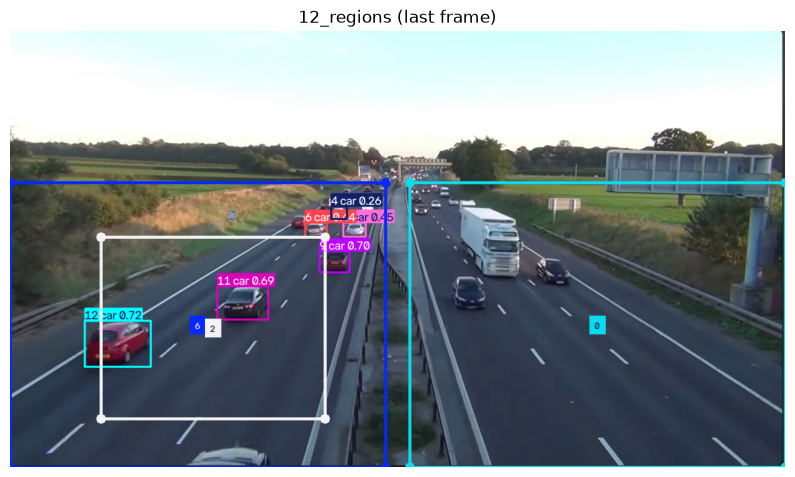

Speed: 23 frames per second (the video has 30)
Vehicles in each area (last frame): {'Left road': 6, 'Right road': 0, 'Left small road': 2}


In [52]:
regions = solutions.RegionCounter(model="yolo26n.pt", region=REGIONS, classes=VEHICLES, show=False, verbose=False)


def step(frame):
    return regions.process(frame).plot_im


run_video(step, "12_regions")
print("Vehicles in each area (last frame):", regions.region_counts)

## 15. Track zone
Tracks vehicles only inside one area and ignores the rest. Example: only the right side of the road.

In [53]:
REGIONS = {
    "Left road": [(0, 250), (620, 250), (620, 720), (0, 720)],
    "Right road": [(660, 250), (1280, 250), (1280, 720), (660, 720)],
    "Left small road": [(150, 340), (520, 340), (520, 640), (150, 640)],
}

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': [(150, 340), (520, 340), (520, 640), (150, 640)], 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


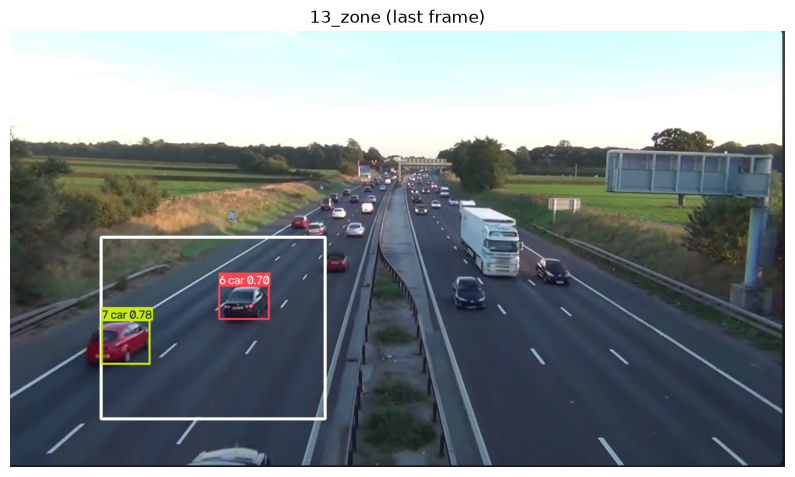

Speed: 24 frames per second (the video has 30)


In [54]:
zone = solutions.TrackZone(model="yolo26n.pt", region=REGIONS["Left small road"], classes=VEHICLES, show=False, verbose=False)

def step(frame):
    return zone.process(frame).plot_im


run_video(step, "13_zone")

## 16. Vision eye
Draws a line from one fixed point to every vehicle. Example: the point is the camera position, at the bottom centre.

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (640, 700), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


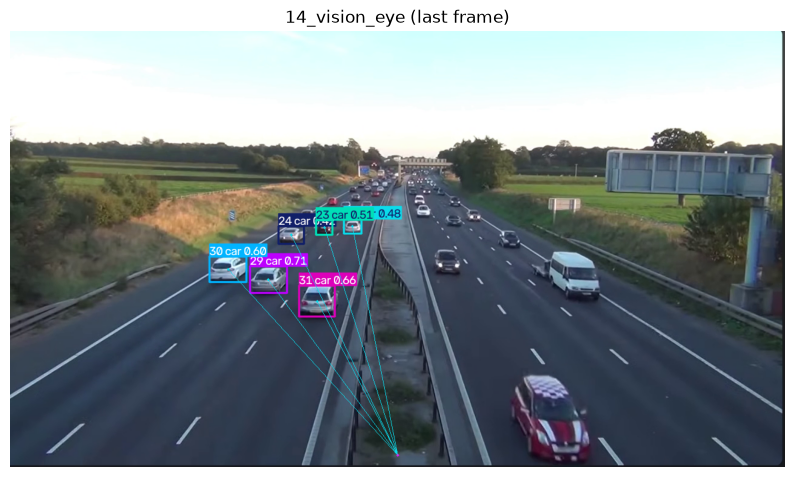

Speed: 24 frames per second (the video has 30)


In [16]:
eye = solutions.VisionEye(model="yolo26n.pt", vision_point=(640, 700), classes=VEHICLES, show=False, verbose=False)


def step(frame):
    return eye.process(frame).plot_im


run_video(step, "14_vision_eye")

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (380, 480), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


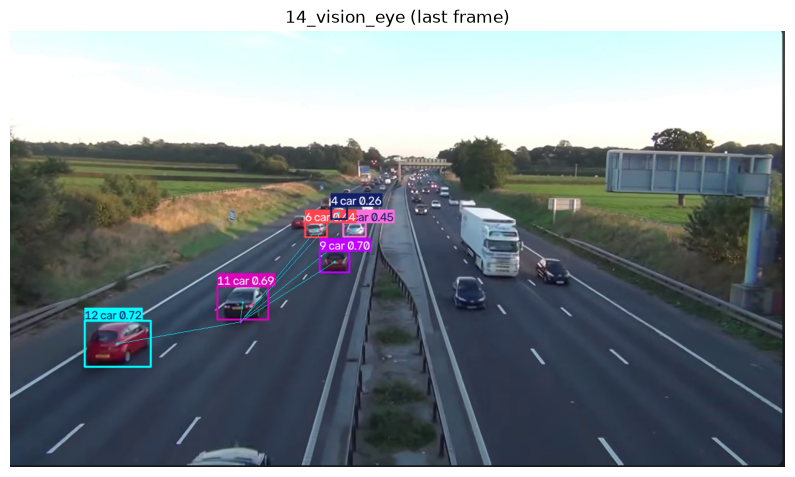

Speed: 23 frames per second (the video has 30)


In [55]:
eye = solutions.VisionEye(model="yolo26n.pt", vision_point=(380, 480), classes=VEHICLES, show=False, verbose=False)


def step(frame):
    return eye.process(frame).plot_im


run_video(step, "14_vision_eye")

## 17. Chart
Replaces the video by a chart that grows over time: the number of vehicles in each frame.

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


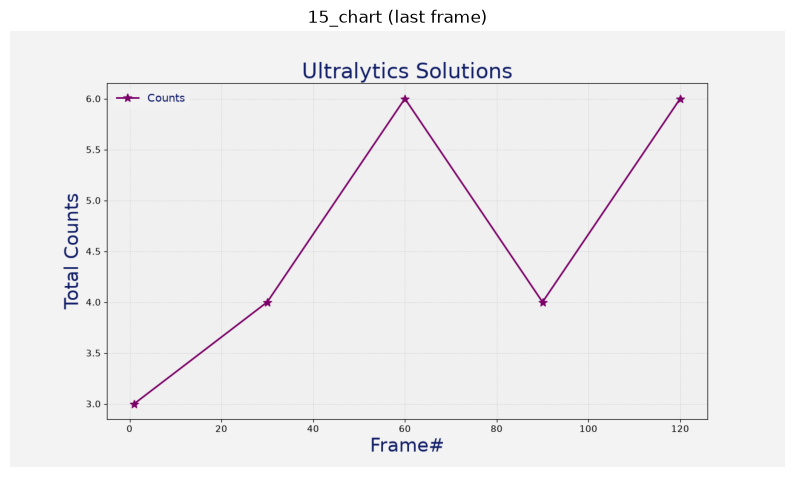

Speed: 53 frames per second (the video has 30)


In [17]:
chart = solutions.Analytics(model="yolo26n.pt", analytics_type="line", classes=VEHICLES, show=False, verbose=False)
frame_number = 0


def step(frame):
    global frame_number
    frame_number += 1
    return chart.process(frame, frame_number=frame_number).plot_im


run_video(step, "15_chart")

## 18. Blur
Blurs every vehicle. Example: privacy. For people, use class `0` (person).

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


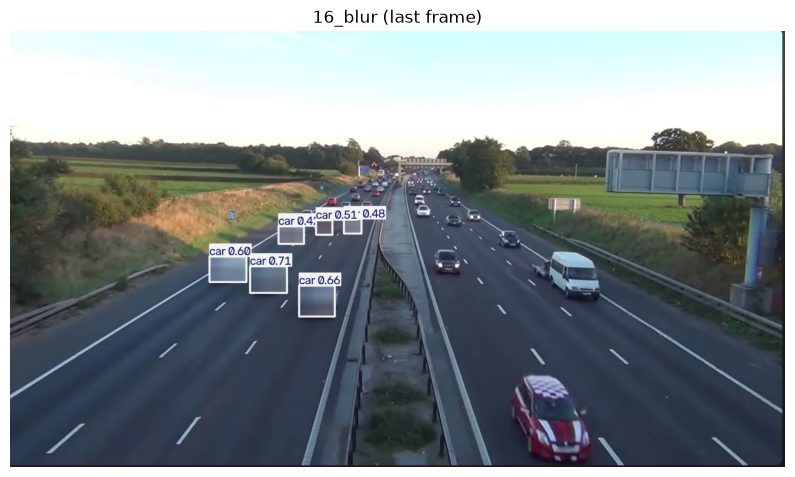

Speed: 25 frames per second (the video has 30)


In [18]:
blurrer = solutions.ObjectBlurrer(model="yolo26n.pt", blur_ratio=0.5, classes=VEHICLES, show=False, verbose=False)


def step(frame):
    return blurrer.process(frame).plot_im


run_video(step, "16_blur")

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.95, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


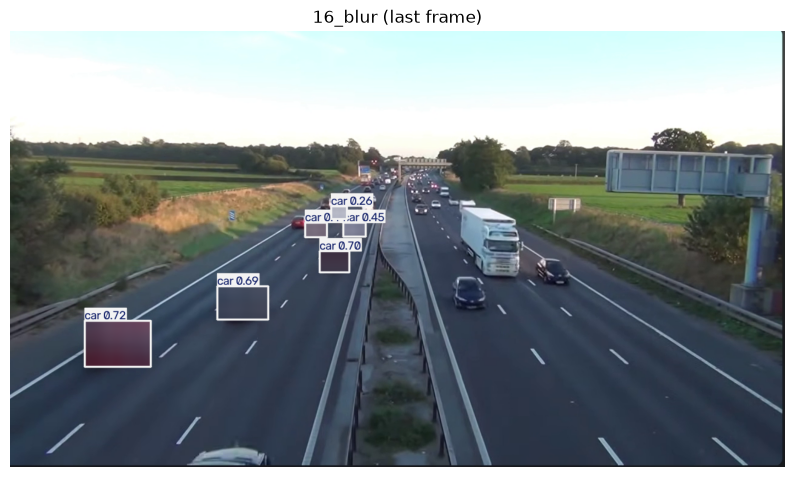

Speed: 23 frames per second (the video has 30)


In [59]:
blurrer = solutions.ObjectBlurrer(model="yolo26n.pt", blur_ratio=0.95, classes=VEHICLES, show=False, verbose=False)

def step(frame):
    return blurrer.process(frame).plot_im

run_video(step, "16_blur")